### **EDA - Data Analysis**


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("../dataset/raw/Crop_Recommendation1_Dataset_AtharvaIngle.csv")

In [5]:
print(df.head())
print(df.shape)
print(df.columns.tolist())
print(df.isnull().sum())

    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice
(2200, 8)
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


In [6]:
print("Crops Available: ", df["label"].unique())
print("Total Crops: ", df["label"].nunique())

Crops Available:  ['rice' 'maize' 'chickpea' 'kidneybeans' 'pigeonpeas' 'mothbeans'
 'mungbean' 'blackgram' 'lentil' 'pomegranate' 'banana' 'mango' 'grapes'
 'watermelon' 'muskmelon' 'apple' 'orange' 'papaya' 'coconut' 'cotton'
 'jute' 'coffee']
Total Crops:  22


In [7]:
print(df["label"].value_counts())

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


In [8]:
for col in df.columns:
    print(col, ":", df[col].nunique())

N : 137
P : 117
K : 73
temperature : 2200
humidity : 2200
ph : 2200
rainfall : 2200
label : 22


In [9]:
print(df.isnull().sum())
print("Total null values:", df.isnull().sum().sum())

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64
Total null values: 0


### Graphs and Charts


Graph 1: Crop Class Distribution


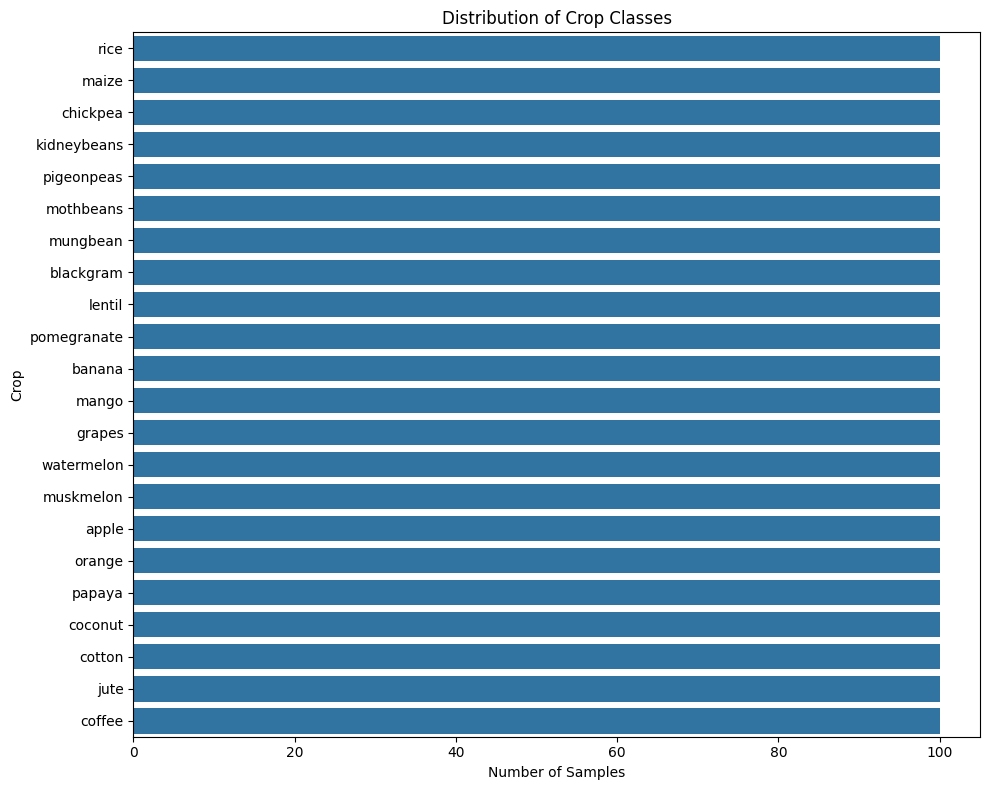

In [10]:
plt.figure(figsize=(10, 8))

sns.countplot(data=df, y="label", order=df["label"].value_counts().index)

plt.title("Distribution of Crop Classes")
plt.xlabel("Number of Samples")
plt.ylabel("Crop")
plt.tight_layout()
plt.show()

Graph 2: Histograms of numerical features


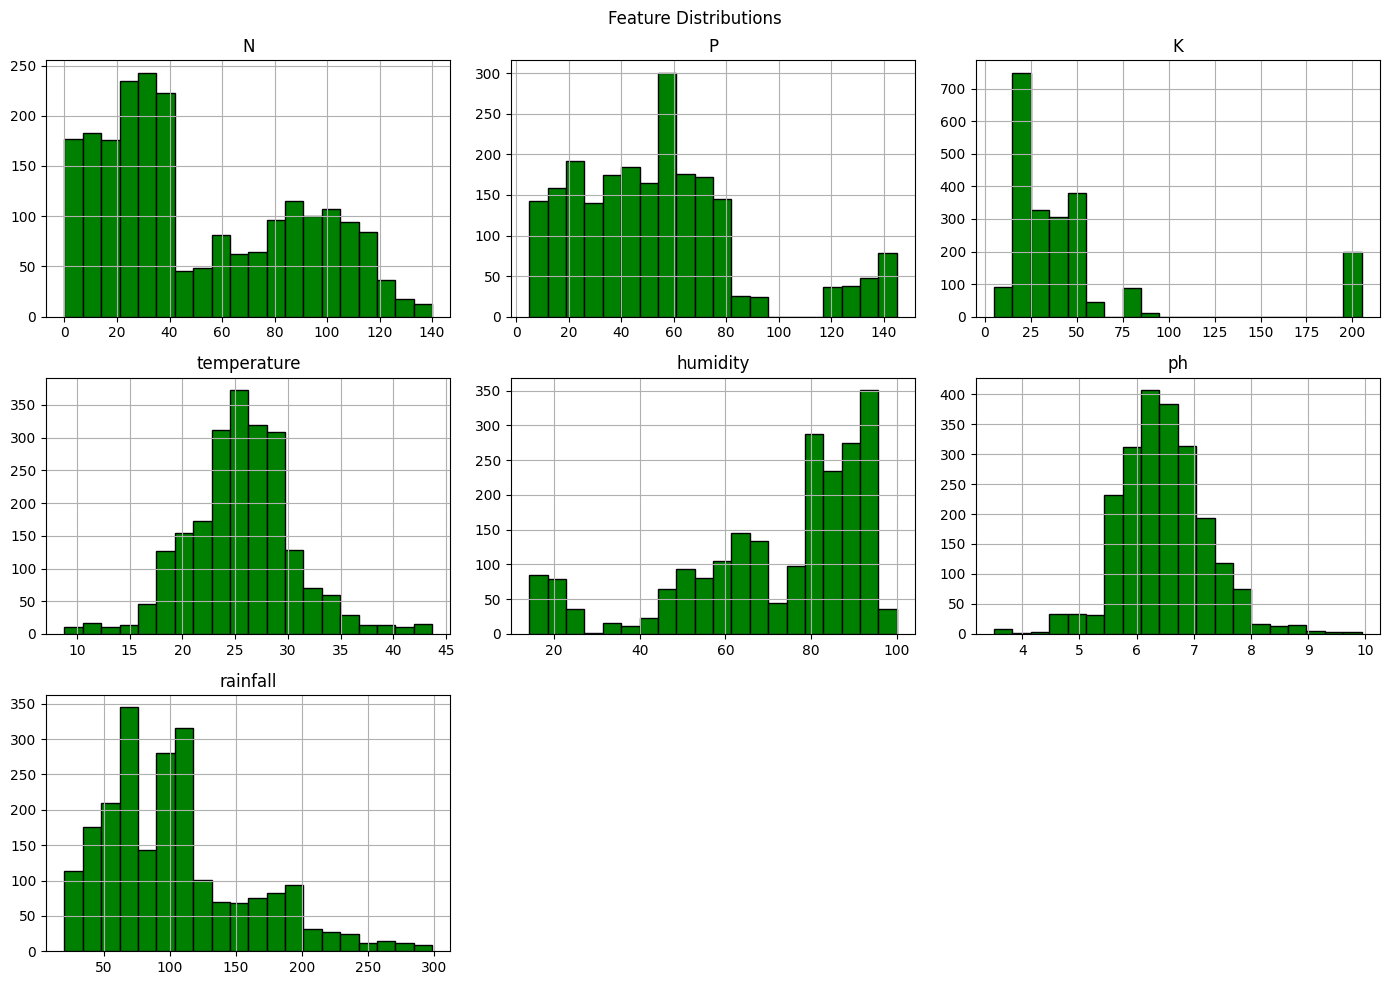

In [11]:
df.hist(figsize=(14, 10), bins=20, edgecolor="black", color="green")

plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

Graph 3: Correlation heatmap

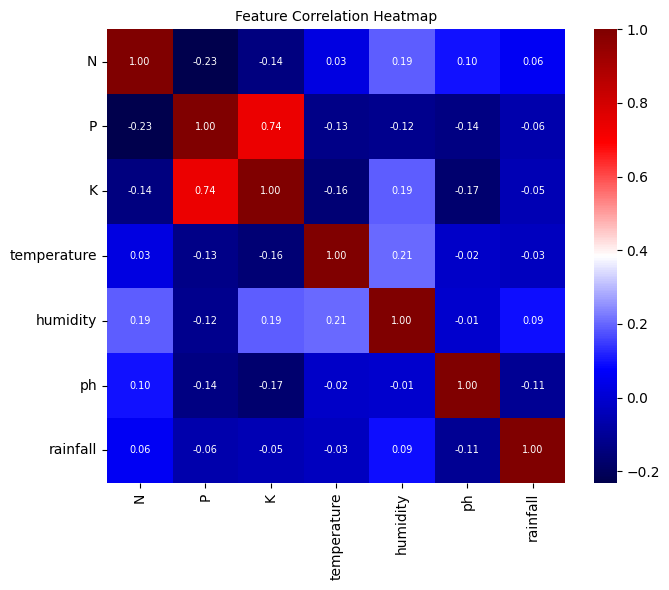

In [12]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(7, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="seismic",
    fmt=".2f",
    annot_kws={"size": 7}
)

plt.title("Feature Correlation Heatmap", fontsize=10)
plt.tight_layout()
plt.show()

Graph 4: Box plots for outliers

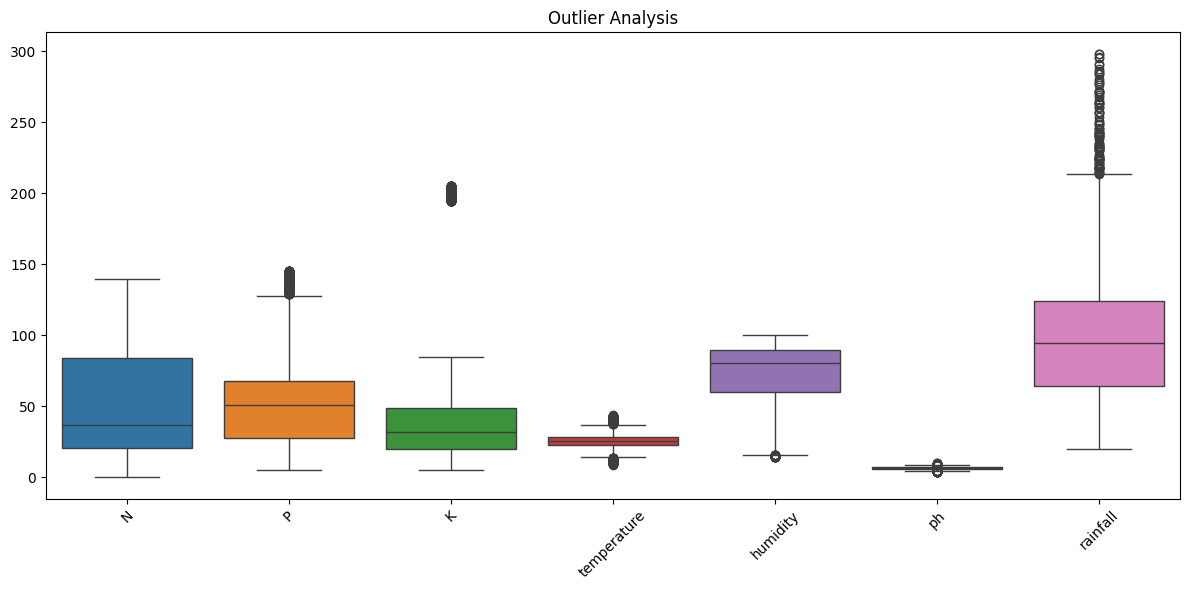

In [13]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 6))
sns.boxplot(data=numeric_df)
plt.xticks(rotation=45)
plt.title("Outlier Analysis")
plt.tight_layout()
plt.show()

Graph 5: Compare two features by crop

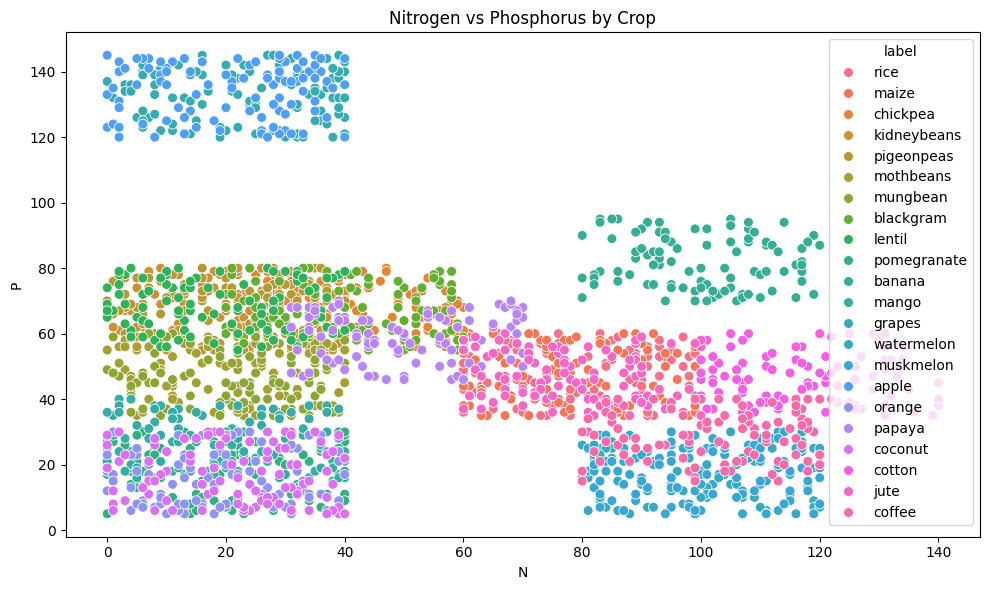

In [14]:
# N vs P
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="N",
    y="P",
    hue="label",
    s=50
)
plt.title("Nitrogen vs Phosphorus by Crop")
plt.tight_layout()
plt.show()

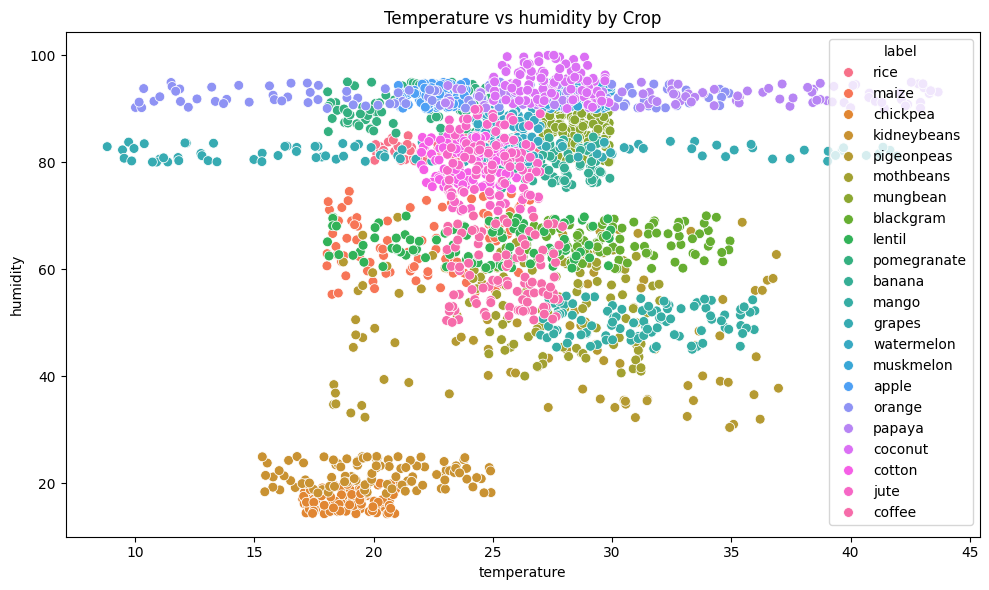

In [15]:
# Temperature vs humidity
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="temperature",
    y="humidity",
    hue="label",
    s=50
)
plt.title("Temperature vs humidity by Crop")
plt.tight_layout()
plt.show()

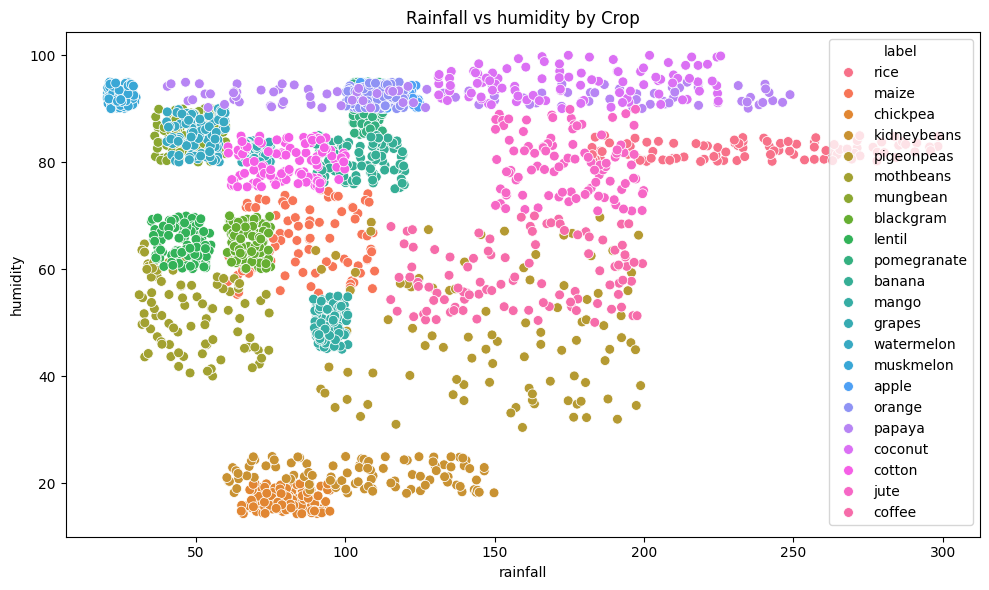

In [16]:
# Rainfall vs humidity
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="rainfall",
    y="humidity",
    hue="label",
    s=50
)
plt.title("Rainfall vs humidity by Crop")
plt.tight_layout()
plt.show()

Graph 6: Rainfall distribution across crops

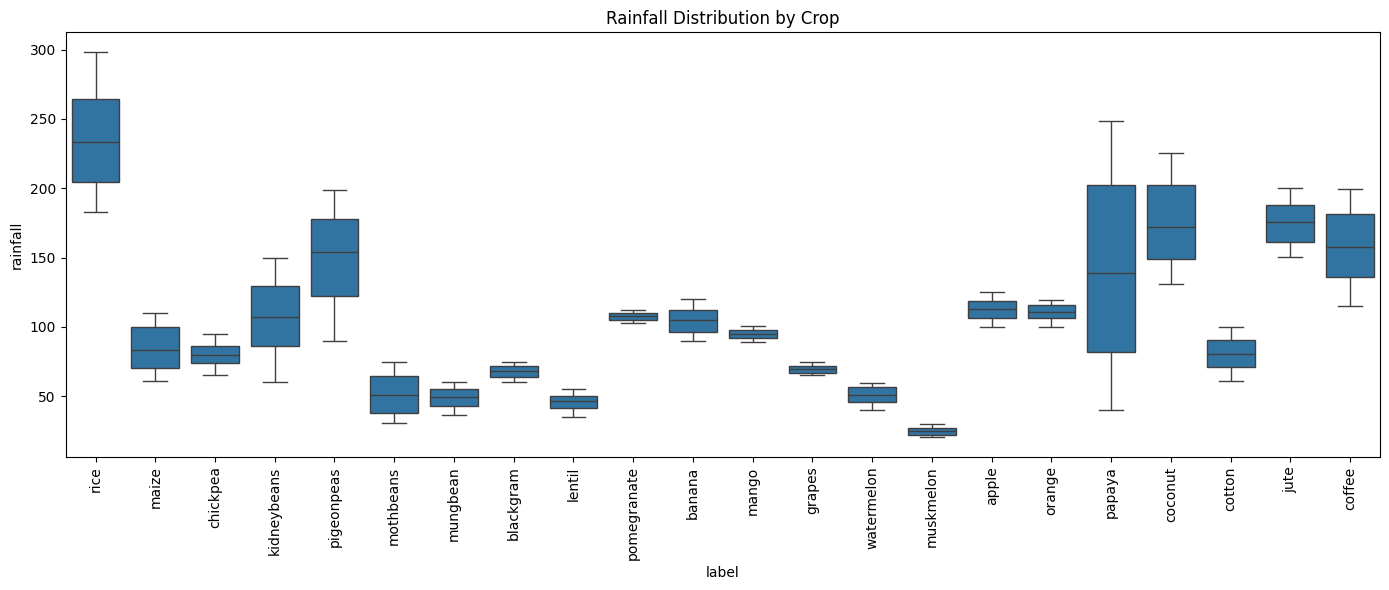

In [17]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x="label",
    y="rainfall"
)
plt.xticks(rotation=90)
plt.title("Rainfall Distribution by Crop")
plt.tight_layout()
plt.show()

Graph All

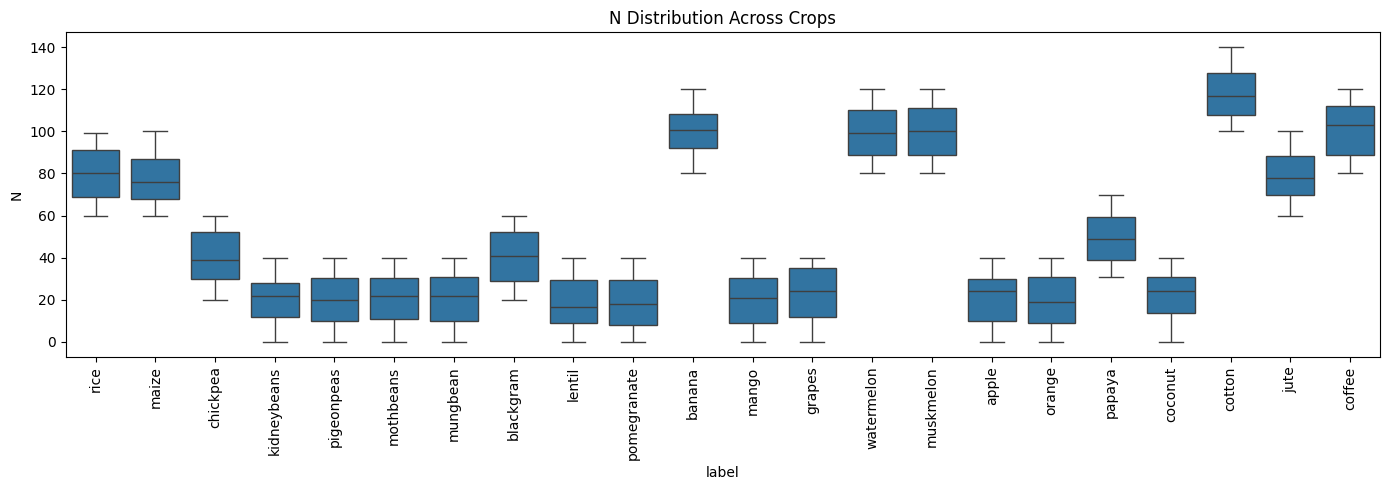

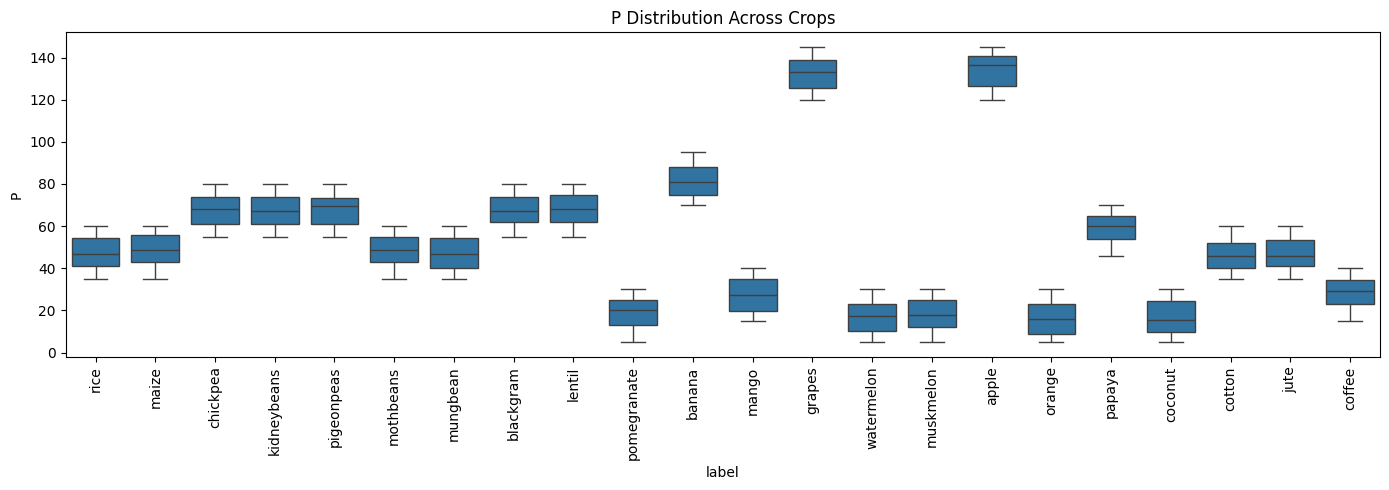

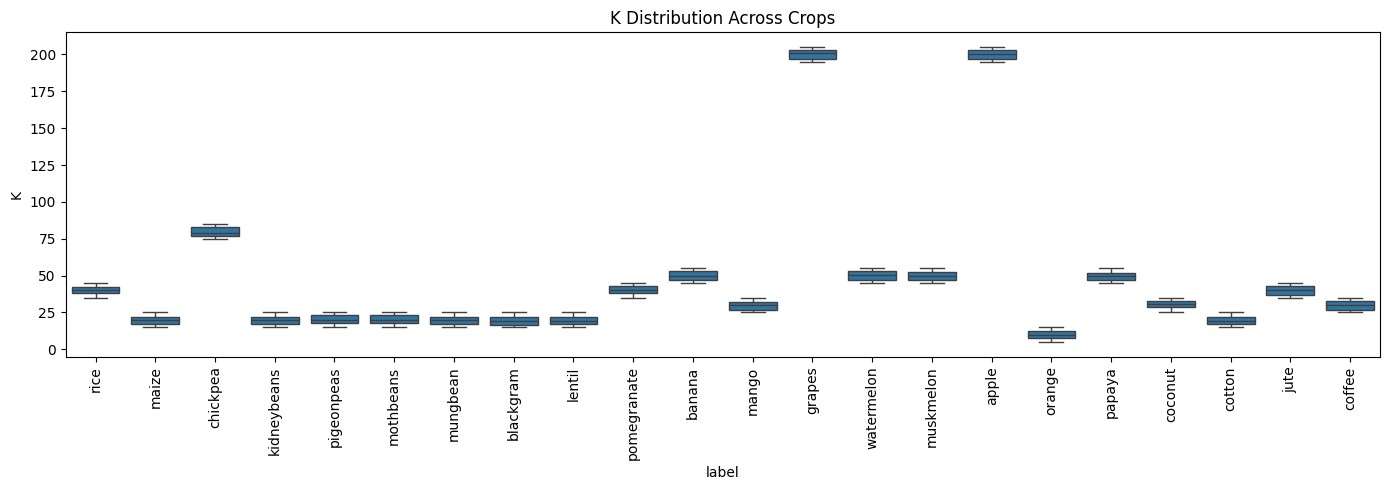

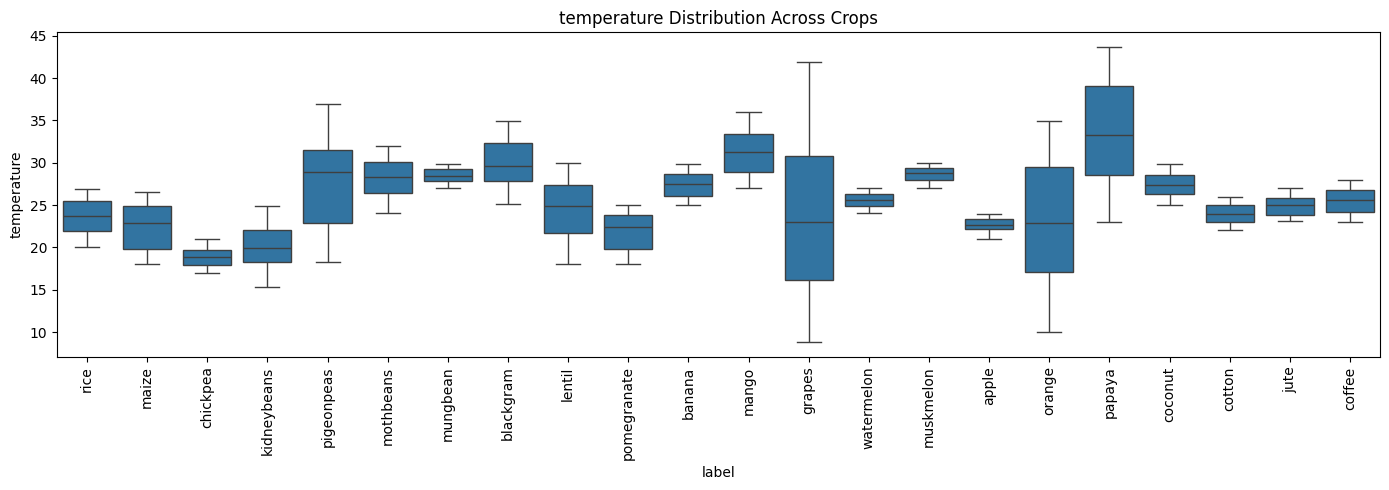

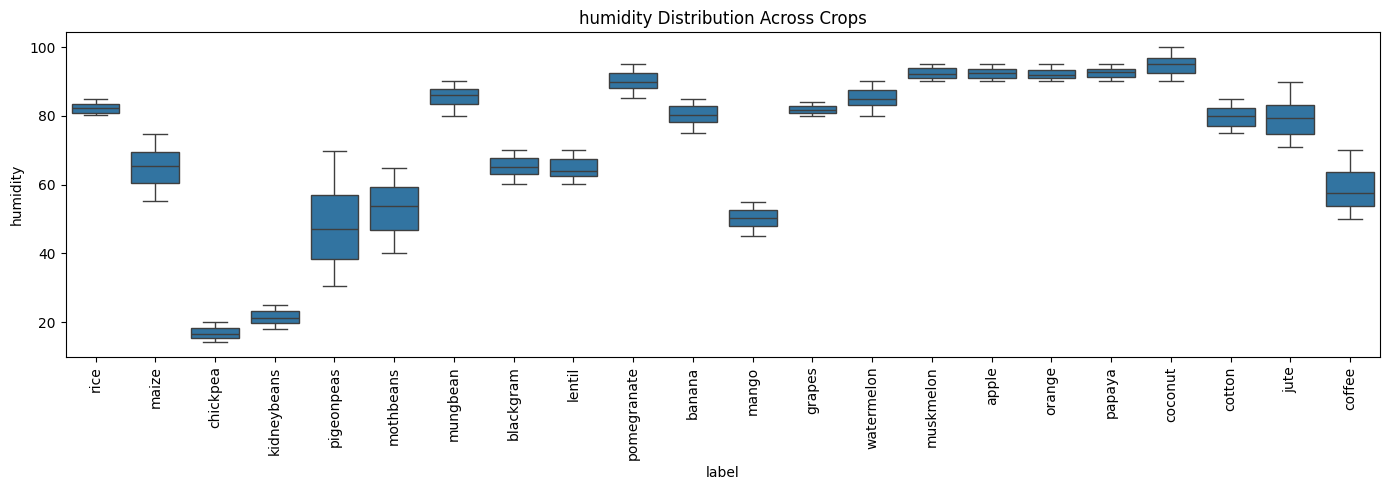

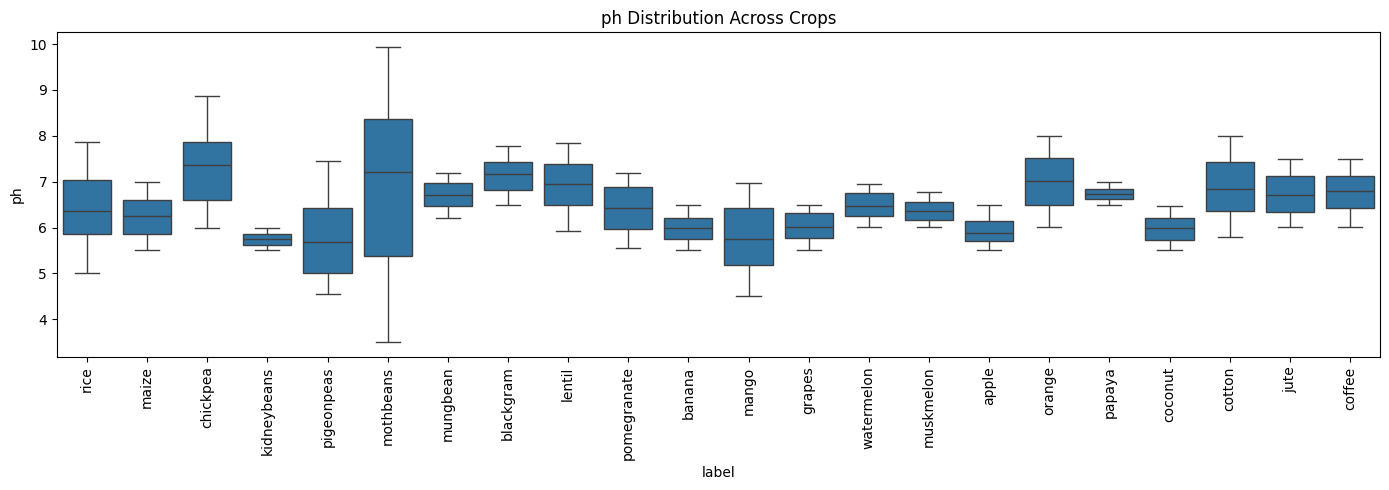

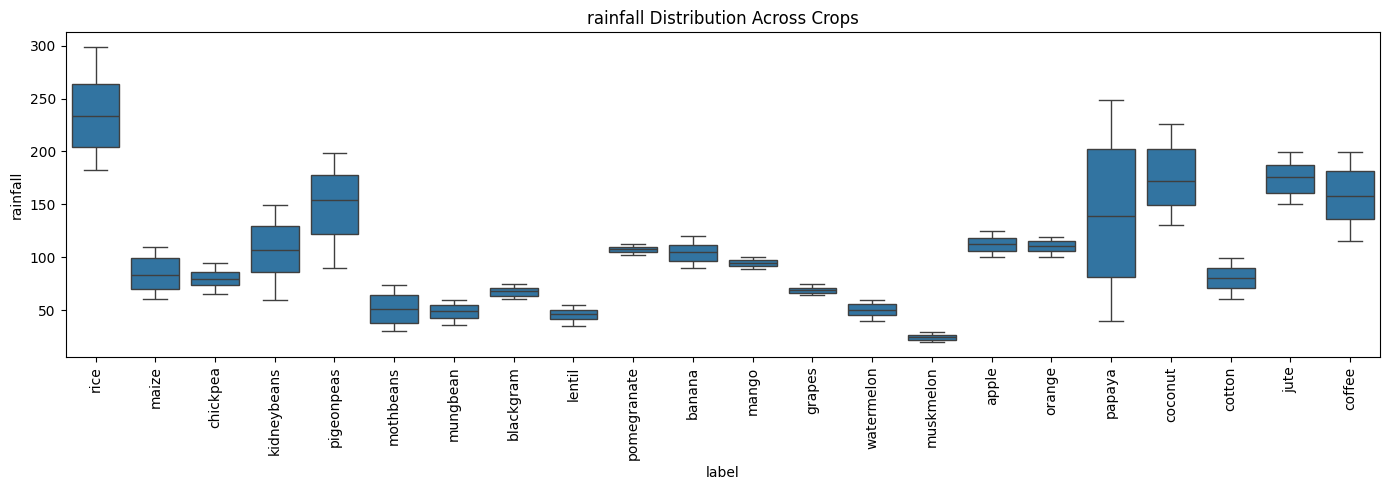

In [18]:
features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

for feature in features:
    plt.figure(figsize=(14, 5))

    sns.boxplot(data=df, x="label", y=feature)

    plt.xticks(rotation=90)
    plt.title(f"{feature} Distribution Across Crops")
    plt.tight_layout()
    plt.show()

### Split dataset

2.1 Separate features (X) and target (y)

In [19]:
x = df.drop(columns=["label"])
y = df["label"]

print("Features:", x.columns.tolist())
print("Target:", y.name)

print("X shape:", x.shape)
print("y shape:", y.shape)

Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Target: label
X shape: (2200, 7)
y shape: (2200,)


2.2 Split into training and testing data

In [20]:
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay

print("Scikit-learn version:", sklearn.__version__)
print("Imports successful!")

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

Scikit-learn version: 1.9.1
Imports successful!
Training samples: 1760
Testing samples: 440


In [21]:
# print(x_train)
# print(y_train)
# print(x_test)
# print(y_test)

Create a folder and save the datasets

In [22]:
# Save features
x_train.to_csv("../dataset/splits/x_train.csv", index=False)
x_test.to_csv("../dataset/splits/x_test.csv", index=False)

# Save labels
y_train.to_csv("../dataset/splits/y_train.csv", index=False)
y_test.to_csv("../dataset/splits/y_test.csv", index=False)

print("Datasets saved successfully!")

Datasets saved successfully!


> How to load them later

In [23]:
x_train = pd.read_csv("../dataset/splits/x_train.csv")
x_test = pd.read_csv("../dataset/splits/x_test.csv")

y_train = pd.read_csv("../dataset/splits/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../dataset/splits/y_test.csv").squeeze("columns")

### Decision Tree Model - 1

1.1 Train a Decision Tree

In [24]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(x_train, y_train)
dt_predictions = dt_model.predict(x_test)

print(dt_predictions)

['orange' 'banana' 'cotton' 'maize' 'orange' 'chickpea' 'rice' 'blackgram'
 'banana' 'orange' 'watermelon' 'pomegranate' 'watermelon' 'maize'
 'mothbeans' 'grapes' 'grapes' 'mango' 'mango' 'apple' 'blackgram' 'apple'
 'mothbeans' 'kidneybeans' 'apple' 'jute' 'mothbeans' 'watermelon' 'rice'
 'coffee' 'mango' 'jute' 'banana' 'coffee' 'jute' 'blackgram' 'grapes'
 'grapes' 'blackgram' 'jute' 'coconut' 'papaya' 'mango' 'maize' 'lentil'
 'jute' 'cotton' 'lentil' 'chickpea' 'mungbean' 'papaya' 'pomegranate'
 'pigeonpeas' 'watermelon' 'mango' 'lentil' 'papaya' 'papaya' 'coffee'
 'lentil' 'lentil' 'mothbeans' 'coffee' 'banana' 'papaya' 'rice' 'orange'
 'coconut' 'blackgram' 'pomegranate' 'banana' 'muskmelon' 'watermelon'
 'lentil' 'banana' 'coconut' 'mothbeans' 'mungbean' 'mungbean' 'mango'
 'coffee' 'watermelon' 'muskmelon' 'kidneybeans' 'mango' 'pomegranate'
 'orange' 'cotton' 'coconut' 'papaya' 'mothbeans' 'mungbean' 'mothbeans'
 'cotton' 'jute' 'grapes' 'cotton' 'chickpea' 'jute' 'watermelo

1.2 Evaluate the Decision Tree

- Precision: Of the samples predicted as a particular crop, how many were correct?
- Recall: Of the actual samples of that crop, how many did the model identify?
- F1-score: A combined measure of precision and recall.
- Support: Number of actual test samples belonging to each crop.

In [25]:
from sklearn.metrics import accuracy_score, classification_report

print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_predictions))

print(classification_report(y_test, dt_predictions))

Decision Tree Accuracy: 0.9795454545454545
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.80      0.89        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      0.95      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.86      0.90      0.88        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.86      0.95      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00     

### Random Forest - 2

2.1 Train a Random Forest

In [26]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(x_train, y_train)

rf_predictions = rf_model.predict(x_test)

2.2 Evaluate the Random Forest

In [27]:
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

print(classification_report(y_test, rf_predictions))

Random Forest Accuracy: 0.9954545454545455
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00     

### K-Nearest Neighbors (KNN) - 3

3.1 KNN predicts a crop based on the labels of the most similar training samples.

In [28]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(x_train, y_train)
knn_predictions = knn_model.predict(x_test)

print("KNN Accuracy:",
      accuracy_score(y_test, knn_predictions))

print(classification_report(y_test, knn_predictions))

KNN Accuracy: 0.9772727272727273
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       0.91      1.00      0.95        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       0.95      1.00      0.98        20
      grapes       1.00      1.00      1.00        20
        jute       0.78      0.90      0.84        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      0.95      0.97        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      0.95      0.97        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00     

### Support Vector Machine (SVM) - 4

4.1 Train a SVM

In [29]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)
svm_model.fit(x_train, y_train)
svm_predictions = svm_model.predict(x_test)

print("SVM Accuracy:",
      accuracy_score(y_test, svm_predictions))

print(classification_report(y_test, svm_predictions))

SVM Accuracy: 0.9840909090909091
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       0.91      1.00      0.95        20
      grapes       1.00      1.00      1.00        20
        jute       0.87      1.00      0.93        20
 kidneybeans       0.95      1.00      0.98        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      0.90      0.95        20
       mango       0.95      1.00      0.98        20
   mothbeans       1.00      0.95      0.97        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00     

### XGBoost - 5

5.1 Train XGBoost

In [30]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# Encode crop labels as integers for XGBoost
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Create model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="mlogloss",
    n_jobs=-1
)


xgb_model.fit(x_train, y_train_encoded)
xgb_predictions_encoded = xgb_model.predict(x_test)

# Convert predictions back to crop names
xgb_predictions = label_encoder.inverse_transform(
    xgb_predictions_encoded.astype(int)
)

In [31]:
# Evaluate the XGBoost 
print("XGBoost Accuracy:",
      accuracy_score(y_test, xgb_predictions))
print(classification_report(y_test, xgb_predictions))

XGBoost Accuracy: 0.9863636363636363
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       0.95      1.00      0.98        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.91      1.00      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.85      0.92        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98        20
    mungbean       0.91      1.00      0.95        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00 

### Compare ALL 5 models

In [32]:
# Compare accuracy and macro F1-score  ( # Not needed # )

from sklearn.metrics import f1_score

models_predictions = {
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions,
    "SVM": svm_predictions
}

results = []

for name, predictions in models_predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test, predictions, average="macro"
        )
    })

results_df = pd.DataFrame(results).sort_values(
    "Macro F1", ascending=False
)

print(results_df.to_string(index=False))

        Model  Accuracy  Macro F1
Random Forest  0.995455  0.995452
      XGBoost  0.986364  0.986210
          SVM  0.984091  0.984038
Decision Tree  0.979545  0.979423


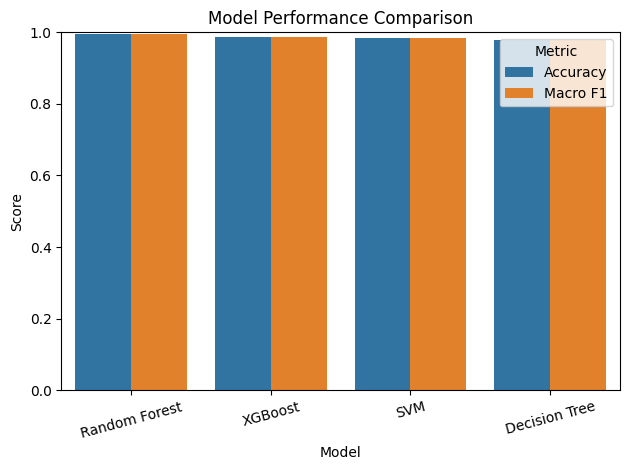

In [33]:
# Visualize F1_score and Accuracy of all Model
results_long = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Macro F1"],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=results_long,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Model Performance Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [34]:
# Compare all accuracy score of all model.
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "KNN",
        "XGBoost",
        "SVM"
    ],
    "Accuracy": [
        accuracy_score(y_test, dt_predictions) * 100,
        accuracy_score(y_test, rf_predictions) * 100,
        accuracy_score(y_test, knn_predictions) * 100,
        accuracy_score(y_test, svm_predictions) * 100,
        accuracy_score(y_test, xgb_predictions) * 100
    ]
})

results = results.sort_values(
    by="Accuracy",
    ascending=False
)

print(results)

           Model   Accuracy
1  Random Forest  99.545455
4            SVM  98.636364
3        XGBoost  98.409091
0  Decision Tree  97.954545
2            KNN  97.727273


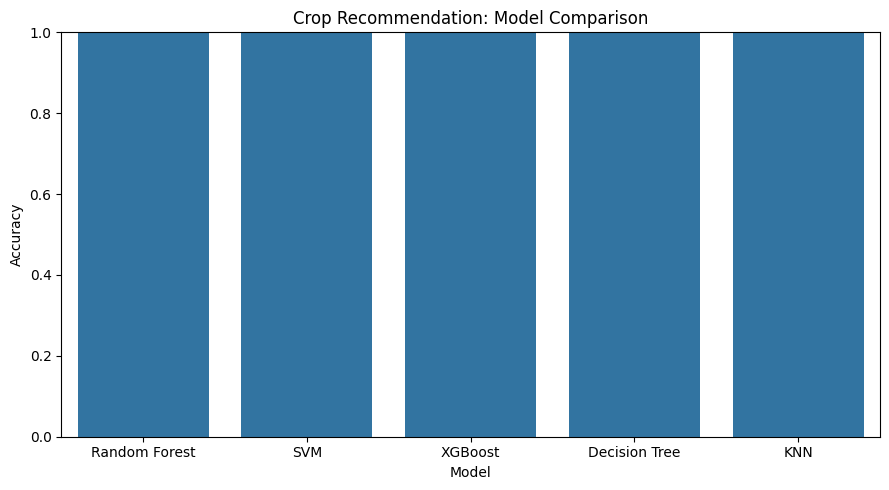

In [35]:
# Visualize the comparison:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy"
)

plt.title("Crop Recommendation: Model Comparison")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### Plot a confusion matrix 
NOTE : A confusion matrix reveals which crops the model confuses with one another.

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# cm = confusion_matrix(
#     y_test,
#     rf_predictions,
#     labels=rf_model.classes_
# )

# disp = ConfusionMatrixDisplay(
#     confusion_matrix=cm,
#     display_labels=rf_model.classes_
# )

# disp.plot(
#     xticks_rotation=90,
#     cmap="Blues",
#     values_format="d"
# )

# plt.title("Random Forest Confusion Matrix")
# plt.tight_layout()
# plt.show()

Inspect Confusion Matrices of Top 2 Models
- Let's inspect the two models with the highest macro F1 scores.

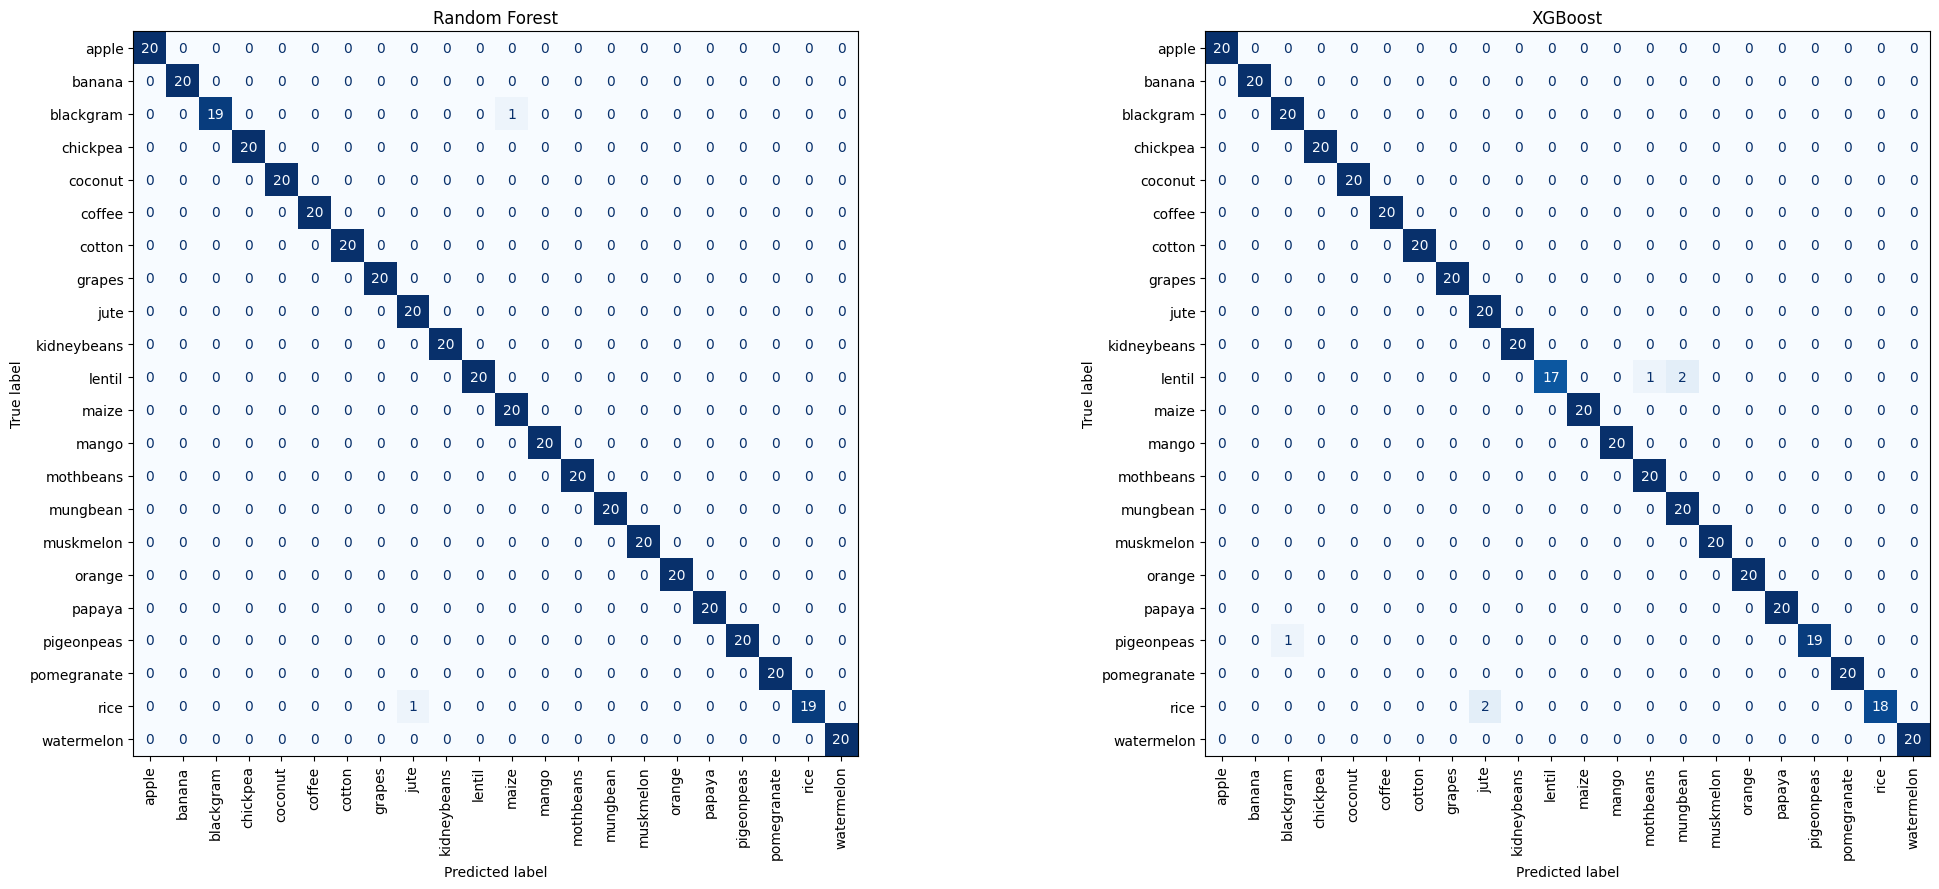

In [37]:
# Random Forest
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(1, 2, figsize=(22, 9))

# Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax[0],
    colorbar=False
)
ax[0].set_title("Random Forest")

# XGBoost
ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_predictions,
    xticks_rotation=90,
    cmap="Blues",
    ax=ax[1],
    colorbar=False
)
ax[1].set_title("XGBoost")

plt.tight_layout()
plt.show()

Step 3. Investigate feature importance

rainfall       23.018423
humidity       22.422659
K              17.539257
P              15.084987
N               9.636333
temperature     7.237530
ph              5.060812
dtype: float64


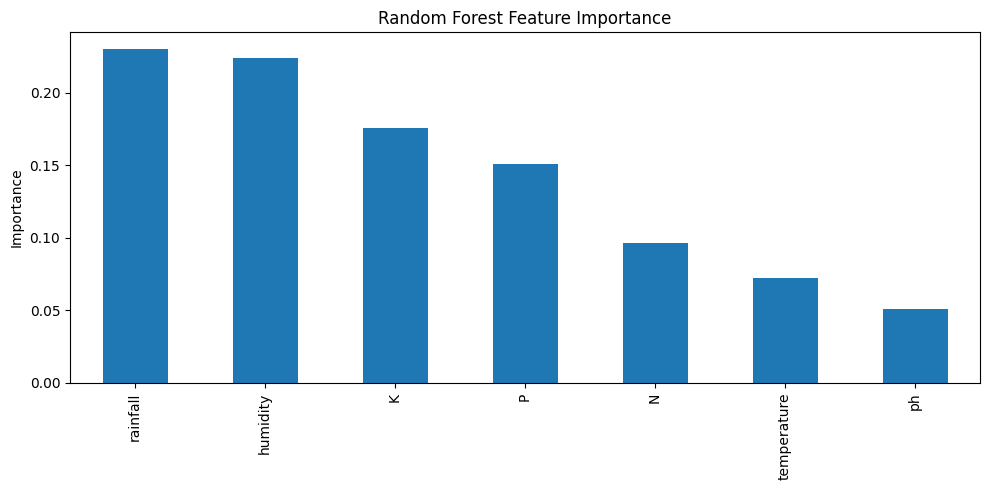

In [39]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=x.columns
).sort_values(ascending=False)

print(importance * 100)

importance.plot(kind="bar", figsize=(10, 5))
plt.title("Random Forest Feature Importance")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

### Save the trained model


In [40]:
import joblib

# Save the trained model
joblib.dump(rf_model, "../models/01_crop_model_rf.pkl")

['../models/01_crop_model_rf.pkl']

In [41]:
model = joblib.load('../models/01_crop_model_rf.pkl')
pred = model.predict(pd.DataFrame([{
    "N": 90,
    "P": 42,
    "K": 43,
    "temperature": 25.5,
    "humidity": 80.0,
    "ph": 6.5,
    "rainfall": 200.0
}]))
print("Recommended crop:", pred[0])

Recommended crop: rice
